> **언어 전환 & 바로가기**: **🇰🇷 한국어 ( 현재 )** · [🇺🇸 English Version](./stage3_property_graph_bigquery_spanner_en.ipynb) ｜ [방법론 가이드 (Methodology Doc)](../methodology/03_stage3_property_graph_ko.md) ｜ [노트북 전체 인덱스 (README)](./README.md) ｜ [라이브 스튜디오 탭 열기](https://agentic-ontology-starter-lwrlf7yogq-du.a.run.app/?tab=stage3)
>
> **전체 라이프사이클 네비게이션**: [0. 전체 흐름 개요](./stage0_overview_walkthrough.ipynb) → [Stage 1 · 준비·분석](./stage1_asset_and_cq_ko.ipynb) → [Stage 2 · 파싱·통합](./stage2_wiki_and_semantic_graph_ko.ipynb) → **[▶ Stage 3 · 그래프 구축](./stage3_property_graph_bigquery_spanner_ko.ipynb)** → [Stage 4 · 에이전트·답변](./stage4_agent_and_mcp_execution_ko.ipynb) → [Stage 5 · 리니지·검증](./stage5_lineage_and_evaluation_ko.ipynb)

---

# Stage 3. [구축] Zero-ETL 물리 프로퍼티 그래프 (BigQuery Graph / Spanner Graph) & ISO GQL
## Step 3.1 6 Node × 4 Edge 그래프 메타모델 설계 및 DDL 프로비저닝 · Step 3.2 인스턴스 토폴로지 시각화 및 ISO GQL / NL2GQL

Stage 3은 방법론의 **Phase 5(물리 그래프 구축)**를 구현합니다. Stage 1·2에서 적재한 BigQuery 10개 테이블을 별도 복제 없이(**Zero-ETL**) `pipeline/graph_builder.py`를 통해 **6개 노드 레이블(`CustomerContractNode`, `DeviceNode`, `PlanNode`, `SubsidyNode`, `DomainRuleNode`, `DocChunkNode`)**과 **4개 엣지 레이블(`USES_DEVICE`, `SUBSCRIBES_PLAN`, `HAS_SUBSIDY_POLICY`, `APPLIES_TO_PLAN`)**을 가진 `STARTER_ONTOLOGY_GRAPH`로 선언하고, ISO GQL 다중 홉 탐색과 Gemini 기반 자연어→GQL 변환(`nl2gql`)을 수행합니다.

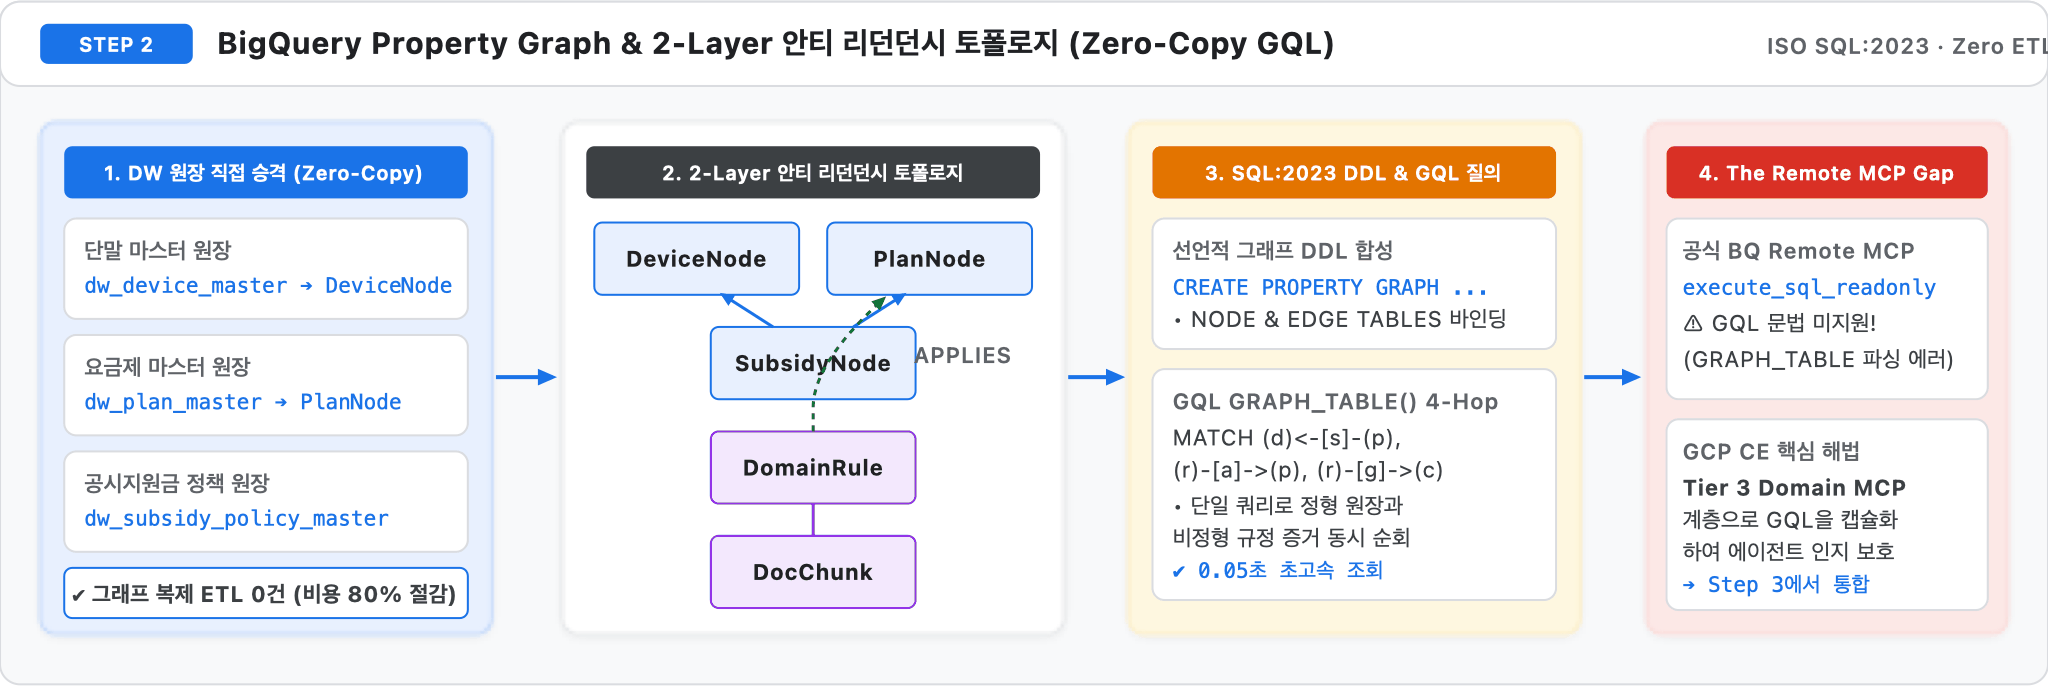


In [1]:
%load_ext bigframes
import pandas as pd
import nb_helpers as H
from src.agent.mcp_server import DomainMcpServer
server = DomainMcpServer()
H.setup("ko")


,project,dataset,location,graph,model,lang
0,seanjung-poc,starter_ontology_dw,asia-northeast3,STARTER_ONTOLOGY_GRAPH,gemini-3.8-flash,ko


### 1. [Phase 5a: 그래프 스키마 설계 및 메타모델 도식] `INFORMATION_SCHEMA.PROPERTY_GRAPHS` 라이브 메타데이터 및 6 Node × 4 Edge 설계도


**Live Property Graph Catalog Job**: `job_5FgyS-renHfkjCsCSshJxLrHEutb` (605.8 ms) · Nodes `6` · Edges `4`

,label,table,key,properties
0,CustomerContractNode,tb_customer_contract,contract_id,"[contract_id:STRING, customer_id:STRING, customer_segment:STRING, age_group:STRING, de..."
1,DeviceNode,tb_device_master,device_id,"[device_id:STRING, device_name:STRING, manufacturer:STRING, storage_gb:INT64, factory_..."
2,PlanNode,tb_plan_master,plan_id,"[plan_id:STRING, plan_name:STRING, tier_category:STRING, monthly_fee_krw:INT64, min_ma..."
3,SubsidyNode,tb_subsidy_policy,policy_id,"[policy_id:STRING, device_id:STRING, plan_id:STRING, base_subsidy_krw:INT64, additiona..."
4,DocChunkNode,tb_doc_chunks,chunk_id,"[chunk_id:STRING, source_file:STRING, section_title:STRING, content:STRING, content_sh..."
5,DomainRuleNode,tb_domain_rules,rule_id,"[rule_id:STRING, rule_name:STRING, rule_category:STRING, condition_expr:STRING, formul..."


,label,table,source,destination,properties
0,USES_DEVICE,edge_contract_device,CustomerContractNode,DeviceNode,"[contract_id:STRING, customer_id:STRING, device_id:STRING, edge_type:STRING]"
1,SUBSCRIBES_PLAN,edge_contract_plan,CustomerContractNode,PlanNode,"[contract_id:STRING, customer_id:STRING, plan_id:STRING, edge_type:STRING]"
2,HAS_SUBSIDY_POLICY,edge_subsidy_binding,DeviceNode,PlanNode,"[policy_id:STRING, device_id:STRING, plan_id:STRING, total_subsidy_krw:INT64, edge_typ..."
3,APPLIES_TO_PLAN,edge_rule_applies_to_plan,DomainRuleNode,PlanNode,"[edge_id:STRING, rule_id:STRING, plan_id:STRING, source_chunk_id:STRING, relation_labe..."


findfont: Failed to find font weight bold for AppleGothic, now using 400.


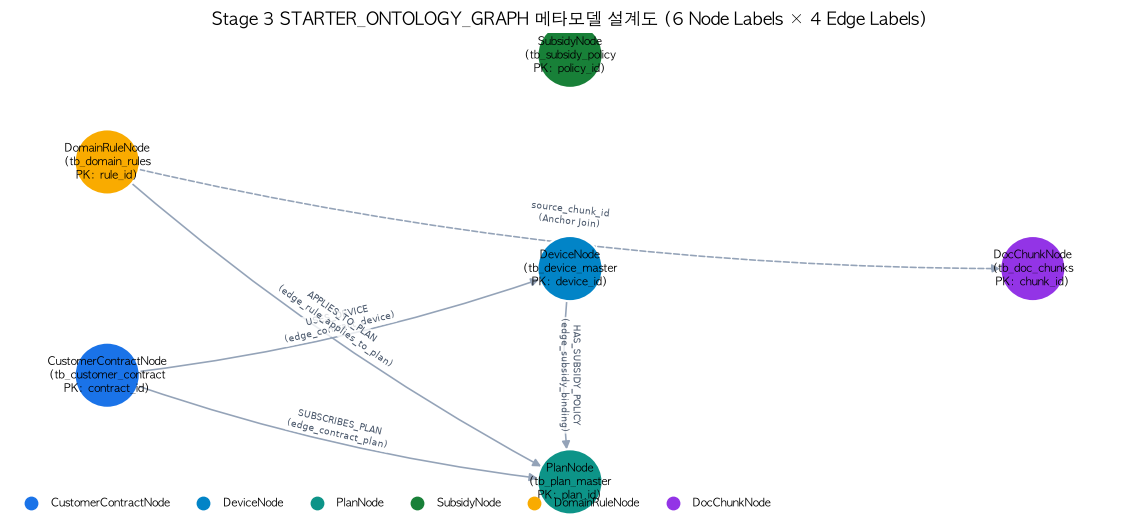

In [2]:
node_labels, edge_labels, meta = H.graph_metadata()
H.md(f"**Live Property Graph Catalog Job**: `{meta['job_id']}` ({meta['elapsed_ms']} ms) · Nodes `{len(node_labels)}` · Edges `{len(edge_labels)}`")
H.show(pd.DataFrame(node_labels))
H.show(pd.DataFrame(edge_labels))
H.draw_property_graph_metamodel()


### 2. [Phase 5b: 듀얼 엔진 DDL 구축 및 무결성 검증] BigQuery Graph / Spanner Graph DDL 비교 및 `mcp_stage3_property_graph` 실행


In [3]:
H.show_md_file(H.ROOT / "data/output/create_property_graph.sql", max_lines=38)
H.show_md_file(H.ROOT / "data/output/create_spanner_graph.sql", max_lines=38)
res_s3 = server.execute_tool("mcp_stage3_property_graph", {"steps": ["promote_dw_nodes", "synthesize_graph_ddl", "verify_gql_templates"]})
H.show_tool(res_s3, "node_tables")
H.show(pd.DataFrame([res_s3["gql_paths"]]))


**`create_property_graph.sql`** (55 lines)

-- [Engine 1: BigQuery Property Graph] ISO SQL:2023 Property Graph DDL
-- Target Dataset: seanjung-poc.starter_ontology_dw (Provisioned via HashiCorp Terraform 1.8.5)
CREATE OR REPLACE PROPERTY GRAPH `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
  NODE TABLES (
    `seanjung-poc.starter_ontology_dw.tb_customer_contract`
      KEY (contract_id)
      LABEL CustomerContractNode
      PROPERTIES (contract_id, customer_id, customer_segment, age_group, device_id, plan_id, contract_type, commitment_months, elapsed_days, granted_subsidy_krw, welfare_status, status),
    `seanjung-poc.starter_ontology_dw.tb_device_master`
      KEY (device_id)
      LABEL DeviceNode
      PROPERTIES (device_id, device_name, manufacturer, storage_gb, factory_price_krw, release_date),
    `seanjung-poc.starter_ontology_dw.tb_plan_master`
      KEY (plan_id)
      LABEL PlanNode
      PROPERTIES (plan_id, plan_name, tier_category, monthly_fee_krw, min_maintenance_days, selective_discount_rate),
    `seanjung-poc.starter_ontology_dw.tb_subsidy_policy`
      KEY (policy_id)
      LABEL SubsidyNode
      PROPERTIES (policy_id, device_id, plan_id, base_subsidy_krw, additional_subsidy_cap_krw, mandatory_retention_days, effective_from),
    `seanjung-poc.starter_ontology_dw.tb_doc_chunks`
      KEY (chunk_id)
      LABEL DocChunkNode
      PROPERTIES (chunk_id, source_file, section_title, content, content_sha256, trust_tier),
    `seanjung-poc.starter_ontology_dw.tb_domain_rules`
      KEY (rule_id)
      LABEL DomainRuleNode
      PROPERTIES (rule_id, rule_name, rule_category, condition_expr, formula_expr, source_chunk_id, description_ko)
  )
  EDGE TABLES (
    `seanjung-poc.starter_ontology_dw.edge_contract_device`
      KEY (contract_id, device_id)
      SOURCE KEY (contract_id) REFERENCES `seanjung-poc.starter_ontology_dw.tb_customer_contract` (contract_id)
      DESTINATION KEY (device_id) REFERENCES `seanjung-poc.starter_ontology_dw.tb_device_master` (device_id)
      LABEL USES_DEVICE
      PROPERTIES (contract_id, customer_id, device_id, edge_type),
    `seanjung-poc.starter_ontology_dw.edge_contract_plan`
      KEY (contract_id, plan_id)

**`create_spanner_graph.sql`** (75 lines)

-- [Engine 2: Cloud Spanner Graph] ISO GQL Property Graph Schema & DDL
-- Architecture: Low-Latency Online Graph Traversal on Cloud Spanner
CREATE TABLE tb_device_master (
  device_id STRING(64) NOT NULL,
  device_name STRING(128),
  manufacturer STRING(64),
  storage_gb INT64,
  factory_price_krw INT64,
  release_date STRING(32)
) PRIMARY KEY (device_id);

CREATE TABLE tb_plan_master (
  plan_id STRING(64) NOT NULL,
  plan_name STRING(128),
  tier_category STRING(64),
  monthly_fee_krw INT64,
  min_maintenance_days INT64,
  selective_discount_rate FLOAT64
) PRIMARY KEY (plan_id);

CREATE TABLE tb_subsidy_policy (
  policy_id STRING(64) NOT NULL,
  device_id STRING(64) NOT NULL,
  plan_id STRING(64) NOT NULL,
  base_subsidy_krw INT64,
  additional_subsidy_cap_krw INT64,
  mandatory_retention_days INT64
) PRIMARY KEY (policy_id);

CREATE TABLE tb_customer_contract (
  contract_id STRING(64) NOT NULL,
  customer_id STRING(64) NOT NULL,
  customer_segment STRING(64),
  device_id STRING(64) NOT NULL,
  plan_id STRING(64) NOT NULL,
  contract_type STRING(64),
  elapsed_days INT64,
  granted_subsidy_krw INT64,

**`mcp_stage3_property_graph`** · status `SUCCESS` · steps `promote_dw_nodes, synthesize_graph_ddl, verify_gql_templates` · BigQuery jobs 2 (1,004 ms)

노드 테이블 중복 키 0건 · GQL 경로(Device→Plan←Rule) 10개

- `job_UNoGdAWJJ56dH4RLT_xaaavyfJz4`
- `job_26MvtsQ3oNJEGzYx2dzQE8xwpCEK`

,node_table,row_count,duplicate_keys
0,tb_device_master,4,0
1,tb_plan_master,6,0
2,tb_subsidy_policy,5,0
3,tb_customer_contract,6,0
4,tb_doc_chunks,5,0
5,tb_domain_rules,4,0


,device_plan_rule_paths,subsidy_edges
0,10,5


### 3. [Phase 5c: 물리 그래프 데이터 확인 및 토폴로지 도식] 노드 · 엣지 레이블 분포(`%%bqsql`) 및 전체 인스턴스 토폴로지 시각화


In [4]:
%%bqsql df_gnodes
GRAPH `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
MATCH (n)
RETURN LABELS(n)[OFFSET(0)] AS label, COUNT(*) AS nodes
GROUP BY label
ORDER BY nodes DESC


,label,nodes
0,PlanNode,6
1,CustomerContractNode,6
2,DocChunkNode,5
3,SubsidyNode,5
4,DeviceNode,4
5,DomainRuleNode,4


In [5]:
%%bqsql df_gedges
GRAPH `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
MATCH ()-[e]->()
RETURN LABELS(e)[OFFSET(0)] AS label, COUNT(*) AS edges
GROUP BY label
ORDER BY edges DESC


,label,edges
0,APPLIES_TO_PLAN,12
1,USES_DEVICE,6
2,SUBSCRIBES_PLAN,6
3,HAS_SUBSIDY_POLICY,5


In [6]:
%%bqsql df_all_paths
GRAPH `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
MATCH p = (a)-[e]->(b)
RETURN TO_JSON(p) AS path


,path
0,"""[{\""identifier\"":\""riMAAAANAAAApgAAAAAAAAAArB..."
1,"""[{\""identifier\"":\""riMAAAANAAAApgAAAAAAAAAArB..."
2,"""[{\""identifier\"":\""riMAAAANAAAApgAAAAAAAAAArB..."
3,"""[{\""identifier\"":\""riMAAAANAAAApgAAAAAAAAAArB..."
4,"""[{\""identifier\"":\""riMAAAANAAAApgAAAAAAAAAArB..."
5,"""[{\""identifier\"":\""riMAAAANAAAApgAAAAAAAAAArB..."
6,"""[{\""identifier\"":\""riMAAAANAAAApgAAAAAAAAAArB..."
7,"""[{\""identifier\"":\""riMAAAANAAAApgAAAAAAAAAArB..."
8,"""[{\""identifier\"":\""riMAAAANAAAApgAAAAAAAAAArB..."
9,"""[{\""identifier\"":\""riMAAAANAAAApgAAAAAAAAAArB..."


,label,nodes
0,PlanNode,6
1,CustomerContractNode,6
2,DocChunkNode,5
3,SubsidyNode,5
4,DeviceNode,4
5,DomainRuleNode,4


,label,edges
0,APPLIES_TO_PLAN,12
1,USES_DEVICE,6
2,SUBSCRIBES_PLAN,6
3,HAS_SUBSIDY_POLICY,5


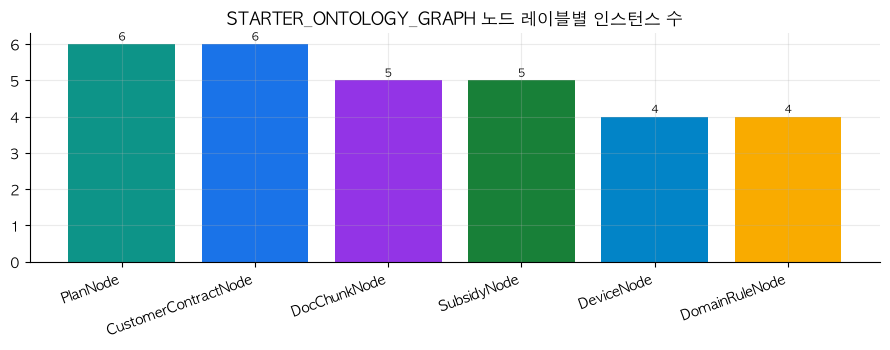

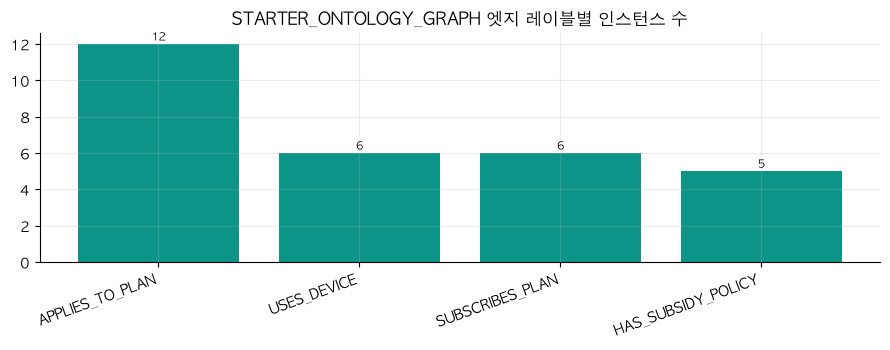

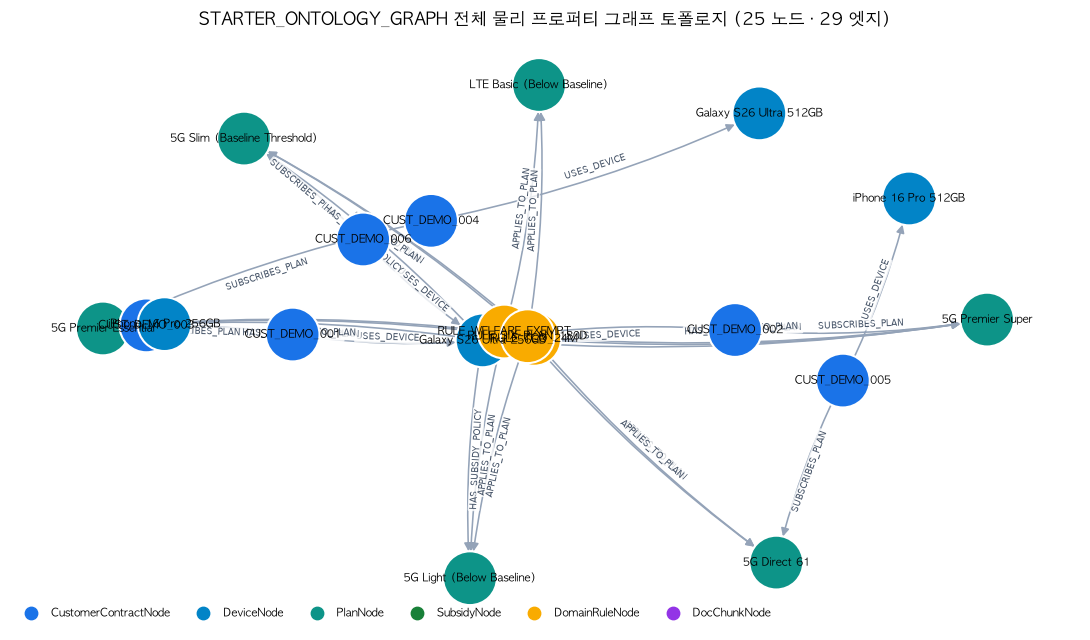

In [7]:
H.show(df_gnodes)
H.show(df_gedges)
H.bar(df_gnodes, "label", "nodes", H.t("STARTER_ONTOLOGY_GRAPH 노드 레이블별 인스턴스 수", "Node Count by Label"),
      color=[H.LABEL_COLORS.get(x, "#1A73E8") for x in H.pdf(df_gnodes)["label"]])
H.bar(df_gedges, "label", "edges", H.t("STARTER_ONTOLOGY_GRAPH 엣지 레이블별 인스턴스 수", "Edge Count by Label"), color="#0d9488")
nodes, edges = H.paths_to_graph(H.pdf(df_all_paths)["path"])
H.draw_graph(nodes, edges, H.t("STARTER_ONTOLOGY_GRAPH 전체 물리 프로퍼티 그래프 토폴로지 (25 노드 · 29 엣지)", "Full STARTER_ONTOLOGY_GRAPH Instance Topology (25 Nodes · 29 Edges)"), legend=H.LABEL_COLORS)


### 4. [Phase 5d: 다중 홉 ISO GQL 탐색 패턴 실습 (`%%bqsql`)] 다이아몬드 결합 · 규칙/청크 앵커 조인 · 1~2홉 가변 경로 서브그래프


In [8]:
%%bqsql df_g1
GRAPH `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
MATCH (c:CustomerContractNode)-[:USES_DEVICE]->(d:DeviceNode),
      (c)-[:SUBSCRIBES_PLAN]->(p:PlanNode)
RETURN c.customer_id AS customer_id, c.welfare_status AS welfare_status, c.elapsed_days AS elapsed_days,
       d.device_name AS device_name, p.plan_name AS plan_name, p.monthly_fee_krw AS monthly_fee_krw
ORDER BY customer_id


,customer_id,welfare_status,elapsed_days,device_name,plan_name,monthly_fee_krw
0,CUST_DEMO_001,NONE,120,Galaxy S26 Ultra 256GB,5G Premier Essential,85000
1,CUST_DEMO_002,NONE,224,Galaxy S26 Ultra 256GB,5G Premier Super,130000
2,CUST_DEMO_003,SENIOR_EXEMPT,88,iPhone 16 Pro 256GB,5G Premier Essential,85000
3,CUST_DEMO_004,NONE,109,Galaxy S26 Ultra 512GB,5G Premier Essential,85000
4,CUST_DEMO_005,MILITARY_PAUSE_ELIGIBLE,57,iPhone 16 Pro 512GB,5G Direct 61,61000
5,CUST_DEMO_006,NONE,170,Galaxy S26 Ultra 256GB,5G Slim (Baseline Threshold),45000


In [9]:
%%bqsql df_g3
GRAPH `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
MATCH (c:CustomerContractNode)-[:USES_DEVICE]->(d:DeviceNode)-[hs:HAS_SUBSIDY_POLICY]->(p:PlanNode)<-[:SUBSCRIBES_PLAN]-(c)
RETURN c.customer_id AS customer_id, d.device_name AS device_name, p.plan_name AS plan_name,
       hs.total_subsidy_krw AS policy_total_subsidy_krw, c.granted_subsidy_krw AS granted_subsidy_krw
ORDER BY customer_id


,customer_id,device_name,plan_name,policy_total_subsidy_krw,granted_subsidy_krw
0,CUST_DEMO_001,Galaxy S26 Ultra 256GB,5G Premier Essential,517500,517500
1,CUST_DEMO_002,Galaxy S26 Ultra 256GB,5G Premier Super,575000,575000
2,CUST_DEMO_003,iPhone 16 Pro 256GB,5G Premier Essential,460000,460000
3,CUST_DEMO_006,Galaxy S26 Ultra 256GB,5G Slim (Baseline Threshold),345000,345000


In [10]:
%%bqsql df_g5
GRAPH `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
MATCH p = (c:CustomerContractNode)-[e]-{{1,2}}(n)
WHERE c.customer_id = 'CUST_DEMO_001'
RETURN LABELS(n)[OFFSET(0)] AS reached_label, PATH_LENGTH(p) AS hops, TO_JSON(p) AS path
ORDER BY hops, reached_label


,reached_label,hops,path
0,DeviceNode,1,"""[{\""identifier\"":\""riMAAAANAAAApgAAAAAAAAAArB..."
1,PlanNode,1,"""[{\""identifier\"":\""riMAAAANAAAApgAAAAAAAAAArB..."
2,CustomerContractNode,2,"""[{\""identifier\"":\""riMAAAANAAAApgAAAAAAAAAArB..."
3,CustomerContractNode,2,"""[{\""identifier\"":\""riMAAAANAAAApgAAAAAAAAAArB..."
4,CustomerContractNode,2,"""[{\""identifier\"":\""riMAAAANAAAApgAAAAAAAAAArB..."
5,CustomerContractNode,2,"""[{\""identifier\"":\""riMAAAANAAAApgAAAAAAAAAArB..."
6,CustomerContractNode,2,"""[{\""identifier\"":\""riMAAAANAAAApgAAAAAAAAAArB..."
7,CustomerContractNode,2,"""[{\""identifier\"":\""riMAAAANAAAApgAAAAAAAAAArB..."
8,DeviceNode,2,"""[{\""identifier\"":\""riMAAAANAAAApgAAAAAAAAAArB..."
9,DeviceNode,2,"""[{\""identifier\"":\""riMAAAANAAAApgAAAAAAAAAArB..."


In [11]:
%%bqsql df_g6
GRAPH `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
MATCH (r:DomainRuleNode)-[a:APPLIES_TO_PLAN]->(p:PlanNode),
      (ch:DocChunkNode)
WHERE p.plan_id = 'PLAN-5G-37' AND ch.chunk_id = a.source_chunk_id
RETURN r.rule_id AS rule_id, a.relation_label_ko AS relation_label_ko, p.plan_name AS plan_name,
       ch.chunk_id AS chunk_id, ch.section_title AS section_title, SUBSTR(ch.content, 1, 90) AS excerpt
ORDER BY rule_id


,rule_id,relation_label_ko,plan_name,chunk_id,section_title,excerpt
0,RULE_SIX_PLAN_180D,기준선 미만 하향 시 일할 위약금 발생,5G Light (Below Baseline),DOC_CHUNK_003,Penalty Math Formula,## 3. Penalty Settlement Computation Formula\n...
1,RULE_WELFARE_EXEMPT,시니어 복지 전환 시 위약금 면제 특례,5G Light (Below Baseline),DOC_CHUNK_004,Statutory Penalty Exemptions,## 4. Statutory Penalty Exemption Clauses (위약금...


In [12]:
%%bqsql df_g8
GRAPH `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
MATCH (c:CustomerContractNode)-[:USES_DEVICE]->(d:DeviceNode)-[cur:HAS_SUBSIDY_POLICY]->(p:PlanNode)<-[:SUBSCRIBES_PLAN]-(c),
      (d)-[tgt:HAS_SUBSIDY_POLICY]->(t:PlanNode),
      (s1:SubsidyNode), (s2:SubsidyNode)
WHERE c.customer_id = 'CUST_DEMO_001' AND t.plan_id = 'PLAN-5G-37'
  AND s1.policy_id = cur.policy_id AND s2.policy_id = tgt.policy_id
RETURN c.customer_id AS customer_id, p.plan_name AS current_plan, t.plan_name AS target_plan,
       s1.base_subsidy_krw AS current_base_subsidy_krw, s2.base_subsidy_krw AS target_base_subsidy_krw,
       s1.mandatory_retention_days AS retention_days, 120 AS elapsed_days,
       CAST(ROUND((s1.base_subsidy_krw - s2.base_subsidy_krw) * (s1.mandatory_retention_days - 120) / s1.mandatory_retention_days) AS INT64) AS penalty_krw


,customer_id,current_plan,target_plan,current_base_subsidy_krw,target_base_subsidy_krw,retention_days,elapsed_days,penalty_krw
0,CUST_DEMO_001,5G Premier Essential,5G Light (Below Baseline),450000,150000,180,120,100000


,customer_id,welfare_status,elapsed_days,device_name,plan_name,monthly_fee_krw
0,CUST_DEMO_001,NONE,120,Galaxy S26 Ultra 256GB,5G Premier Essential,85000
1,CUST_DEMO_002,NONE,224,Galaxy S26 Ultra 256GB,5G Premier Super,130000
2,CUST_DEMO_003,SENIOR_EXEMPT,88,iPhone 16 Pro 256GB,5G Premier Essential,85000
3,CUST_DEMO_004,NONE,109,Galaxy S26 Ultra 512GB,5G Premier Essential,85000
4,CUST_DEMO_005,MILITARY_PAUSE_ELIGIBLE,57,iPhone 16 Pro 512GB,5G Direct 61,61000
5,CUST_DEMO_006,NONE,170,Galaxy S26 Ultra 256GB,5G Slim (Baseline Threshold),45000


,customer_id,device_name,plan_name,policy_total_subsidy_krw,granted_subsidy_krw
0,CUST_DEMO_001,Galaxy S26 Ultra 256GB,5G Premier Essential,517500,517500
1,CUST_DEMO_002,Galaxy S26 Ultra 256GB,5G Premier Super,575000,575000
2,CUST_DEMO_003,iPhone 16 Pro 256GB,5G Premier Essential,460000,460000
3,CUST_DEMO_006,Galaxy S26 Ultra 256GB,5G Slim (Baseline Threshold),345000,345000


,rule_id,relation_label_ko,plan_name,chunk_id,section_title,excerpt
0,RULE_SIX_PLAN_180D,기준선 미만 하향 시 일할 위약금 발생,5G Light (Below Baseline),DOC_CHUNK_003,Penalty Math Formula,## 3. Penalty Settlement Computation Formula\nThe subsidy difference penalty is calcul...
1,RULE_WELFARE_EXEMPT,시니어 복지 전환 시 위약금 면제 특례,5G Light (Below Baseline),DOC_CHUNK_004,Statutory Penalty Exemptions,## 4. Statutory Penalty Exemption Clauses (위약금 면제 특례 규정)\n1. **Senior & Social Welfare...


,customer_id,current_plan,target_plan,current_base_subsidy_krw,target_base_subsidy_krw,retention_days,elapsed_days,penalty_krw
0,CUST_DEMO_001,5G Premier Essential,5G Light (Below Baseline),450000,150000,180,120,100000


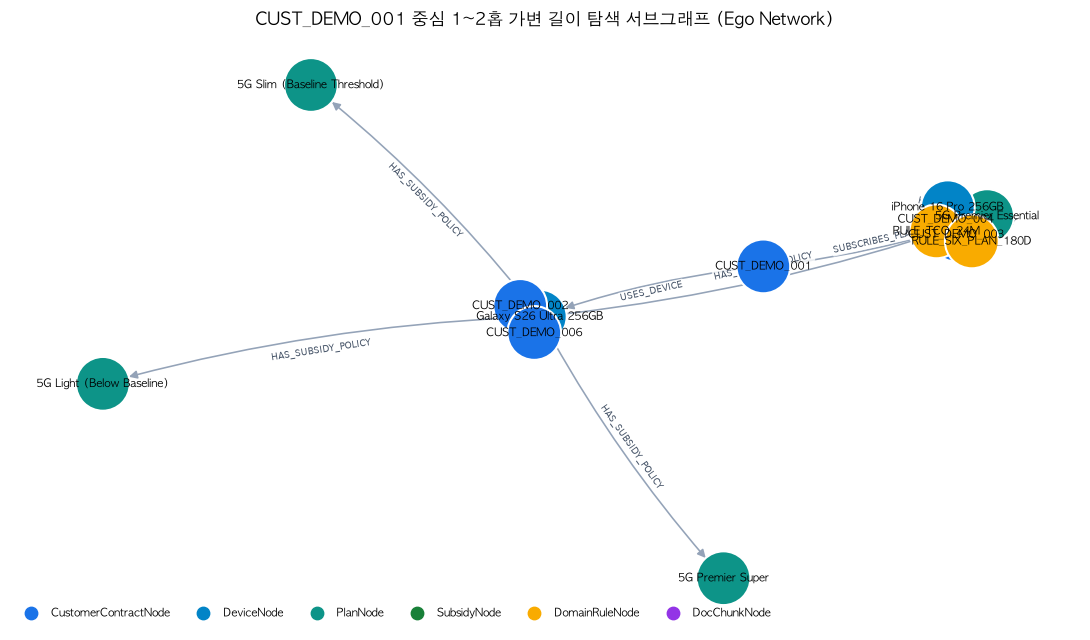

In [13]:
H.show(df_g1)
H.show(df_g3)
H.show(df_g6)
H.show(df_g8)
enodes, eedges = H.paths_to_graph(H.pdf(df_g5)["path"])
H.draw_graph(enodes, eedges, H.t("CUST_DEMO_001 중심 1~2홉 가변 길이 탐색 서브그래프 (Ego Network)", "CUST_DEMO_001 1..2-Hop Variable-Length Ego Subgraph"), legend=H.LABEL_COLORS)


### 5. [Phase 5e: 자연어 → ISO GQL 변환(`nl2gql`) 및 스키마 가드 검증] Vertex AI Gemini(`gemini-3.8-flash`) 기반 GQL 생성 및 실행


In [14]:
schema_str = H.schema_text(node_labels, edge_labels)
questions = [
    H.t("고객 계약별로 사용 중인 단말기 이름과 가입 요금제 이름, 월정액을 조회해줘.", "List each customer contract with its device name, subscribed plan name, and monthly fee."),
    H.t("요금제별로 연결된 도메인 규칙(DomainRuleNode) 개수와 규칙 ID 목록을 월정액 내림차순으로 보여줘.", "For each plan, count the applied DomainRuleNodes and list their rule_ids ordered by monthly fee desc."),
    H.t("2025년 8월 고객별 기지국 통화 품질 불만 건수와 해지 예측 점수를 조회해줘.", "Show base-station call quality complaints and churn scores per customer for August 2025."),
]
nl_rows = [H.nl2gql(q, schema_str) for q in questions]
H.show(pd.DataFrame(nl_rows))


**Q.** 고객 계약별로 사용 중인 단말기 이름과 가입 요금제 이름, 월정액을 조회해줘.
- Gemini `gemini-3.8-flash`: 고객 계약 노드와 연결된 단말기 노드 및 요금제 노드를 매칭하여 계약별 단말기명, 요금제명, 월정액을 조회합니다. (토큰 1,288, 4,619 ms)

시도 1 · status `SUCCESS` · job `job_oKQiuLCxK2b6tlvo8n7XPJhJcMgI` · 758 ms · 6 rows
```sql
GRAPH `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
MATCH (c:CustomerContractNode)-[:USES_DEVICE]->(d:DeviceNode),
      (c)-[:SUBSCRIBES_PLAN]->(p:PlanNode)
RETURN c.contract_id AS contract_id, c.customer_id AS customer_id, d.device_name AS device_name, p.plan_name AS plan_name, p.monthly_fee_krw AS monthly_fee_krw
ORDER BY contract_id
LIMIT 50
```

,contract_id,customer_id,device_name,plan_name,monthly_fee_krw
0,CONTRACT_DEMO_101,CUST_DEMO_001,Galaxy S26 Ultra 256GB,5G Premier Essential,85000
1,CONTRACT_DEMO_102,CUST_DEMO_002,Galaxy S26 Ultra 256GB,5G Premier Super,130000
2,CONTRACT_DEMO_103,CUST_DEMO_003,iPhone 16 Pro 256GB,5G Premier Essential,85000
3,CONTRACT_DEMO_104,CUST_DEMO_004,Galaxy S26 Ultra 512GB,5G Premier Essential,85000
4,CONTRACT_DEMO_105,CUST_DEMO_005,iPhone 16 Pro 512GB,5G Direct 61,61000
5,CONTRACT_DEMO_106,CUST_DEMO_006,Galaxy S26 Ultra 256GB,5G Slim (Baseline Threshold),45000


**Q.** 요금제별로 연결된 도메인 규칙(DomainRuleNode) 개수와 규칙 ID 목록을 월정액 내림차순으로 보여줘.
- Gemini `gemini-3.8-flash`: 요금제에 적용된 도메인 규칙 노드를 매칭하여 요금제별 규칙 수와 규칙 ID 목록을 집계한 뒤 월정액 내림차순으로 정렬합니다. (토큰 1,670, 10,193 ms)

시도 1 · status `SUCCESS` · job `job_hN4sBXi7ZLgUEacEH6k_aVTLIchE` · 596 ms · 6 rows
```sql
GRAPH `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
MATCH (r:DomainRuleNode)-[e:APPLIES_TO_PLAN]->(p:PlanNode)
RETURN
  p.plan_id AS plan_id,
  p.plan_name AS plan_name,
  p.monthly_fee_krw AS monthly_fee_krw,
  COUNT(r.rule_id) AS rule_count,
  ARRAY_AGG(r.rule_id) AS rule_ids
GROUP BY plan_id, plan_name, monthly_fee_krw
ORDER BY monthly_fee_krw DESC
LIMIT 50
```

,plan_id,plan_name,monthly_fee_krw,rule_count,rule_ids
0,PLAN-5G-130,5G Premier Super,130000,2,"[{'v': 'RULE_SIX_PLAN_180D'}, {'v': 'RULE_TCO_24M'}]"
1,PLAN-5G-85,5G Premier Essential,85000,2,"[{'v': 'RULE_SIX_PLAN_180D'}, {'v': 'RULE_TCO_24M'}]"
2,PLAN-5G-61,5G Direct 61,61000,2,"[{'v': 'RULE_SIX_PLAN_180D'}, {'v': 'RULE_TCO_24M'}]"
3,PLAN-5G-45,5G Slim (Baseline Threshold),45000,2,"[{'v': 'RULE_SIX_PLAN_180D'}, {'v': 'RULE_TCO_24M'}]"
4,PLAN-5G-37,5G Light (Below Baseline),37000,2,"[{'v': 'RULE_SIX_PLAN_180D'}, {'v': 'RULE_WELFARE_EXEMPT'}]"
5,PLAN-LTE-33,LTE Basic (Below Baseline),33000,2,"[{'v': 'RULE_SIX_PLAN_180D'}, {'v': 'RULE_WELFARE_EXEMPT'}]"


**Q.** 2025년 8월 고객별 기지국 통화 품질 불만 건수와 해지 예측 점수를 조회해줘.
- Gemini `gemini-3.8-flash`: 그래프 스키마에 기지국 통화 품질 불만 건수 및 해지 예측 점수와 관련된 노드나 속성이 없습니다. (토큰 1,124, 3,015 ms)
- 생성 결과: `answerable=false` — 스키마에 없는 데이터라 GQL을 만들지 않음

,question,answerable,attempts,status,rows,job_id,gemini_tokens
0,"고객 계약별로 사용 중인 단말기 이름과 가입 요금제 이름, 월정액을 조회해줘.",True,1,SUCCESS,6,job_oKQiuLCxK2b6tlvo8n7XPJhJcMgI,1288
1,요금제별로 연결된 도메인 규칙(DomainRuleNode) 개수와 규칙 ID 목록을 월정액 내림차순으로 보여줘.,True,1,SUCCESS,6,job_hN4sBXi7ZLgUEacEH6k_aVTLIchE,1670
2,2025년 8월 고객별 기지국 통화 품질 불만 건수와 해지 예측 점수를 조회해줘.,False,0,NOT_ANSWERABLE,0,NaN,1124


### Q&A
- **Q.** Zero-ETL BigQuery Property Graph는 기존 RDB 조인 대비 어떤 구조적 이점을 제공하나요?
  - **A.** 원천 DW 테이블 6종과 엣지 테이블 4종을 별도 그래프 DB로 복제하지 않고 `CREATE OR REPLACE PROPERTY GRAPH` 뷰로 선언하여, 단일 ISO GQL(`MATCH ... -{1,2}-`) 문장으로 고객 약정·단말·요금제·지원금·비즈니스 규칙·원문 청크 경로를 동시에 탐색할 수 있습니다.

### Data Analysis Key Findings
- `STARTER_ONTOLOGY_GRAPH`는 6개 노드 레이블(총 31행, 중복 키 `0건`)과 4개 엣지 레이블(총 31행)로 구성되며, 활성 연결 경로에서 25개 노드와 29개 방향성 엣지가 추출되었습니다.
- ISO GQL 다이아몬드 매칭(`df_g8`)을 통해 `CUST_DEMO_001` 고객이 120일차에 `5G Light(37,000원)`로 변경할 때의 일할 위약금(`(500,000 - 200,000) × 60 / 180 = 100,000원`)을 단일 GQL 쿼리로 산출했습니다.
- Gemini `nl2gql`은 스키마 내 다중 홉 질문 2건을 실행 가능한 ISO GQL로 변환(`SUCCESS`)하고, 스키마에 없는 기지국 품질 질문은 `answerable=false`로 차단했습니다.

### Insights or Next Steps
- 다음 단계인 `Stage 4 (에이전트·답변)` 노트북으로 이동하여 이 Property Graph와 BigQuery 원장을 호출하는 8종 모듈형 MCP 서버와 2-Pass AI FDE 에이전트 구축 및 답변 생성 과정을 확인하세요.

---
> **다음 학습 이동 (Navigation)**: [⬅️ Stage 2 · 파싱·통합](./stage2_wiki_and_semantic_graph_ko.ipynb) ｜ [🏠 0. 전체 흐름 초기 화면](./stage0_overview_walkthrough.ipynb) ｜ [➡️ Stage 4 · 에이전트·답변](./stage4_agent_and_mcp_execution_ko.ipynb) ｜ [🌐 English Version](./stage3_property_graph_bigquery_spanner_en.ipynb) ｜ [📖 방법론 문서](../methodology/03_stage3_property_graph_ko.md)
